In [1]:
# ==========================================================
# STEP 1: Select Forecasting Algorithm
# ==========================================================

# Algorithm Chosen:
# XGBoost (Extreme Gradient Boosting)

In [2]:
# ==========================================================
# STEP 2: Import Required Libraries
# ==========================================================

# Download stock market data
import yfinance as yf

# Data manipulation and analysis
import pandas as pd

# Mathematical operations
import numpy as np

# Data visualization
import matplotlib.pyplot as plt

# XGBoost regression model
from xgboost import XGBRegressor

# Performance evaluation
from sklearn.metrics import mean_squared_error

In [3]:
# ==========================================================
# STEP 3: Download Historical Stock Dataset
# ==========================================================

# Download Reliance Industries stock data
# Time Period: 2020 - 2025
# Data Source: Yahoo Finance

data = yf.download(
    "RELIANCE.NS",
    start="2020-01-01",
    end="2025-01-01",
    auto_adjust=True
)

print("Dataset Downloaded Successfully")

[*********************100%***********************]  1 of 1 completed

Dataset Downloaded Successfully


In [4]:
# ==========================================================
# STEP 4: Display Raw Dataset
# ==========================================================

data

Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2020-01-01,672.216125,680.008790,670.390471,675.956609,14004468
2020-01-02,683.660217,686.176147,673.284861,673.284861,17710316
2020-01-03,684.484009,686.487835,678.183067,682.636001,20984698
2020-01-06,668.609375,680.365106,667.050830,676.847322,24519177
2020-01-07,678.895630,683.304036,673.952826,676.401934,16683622
...,...,...,...,...,...
2024-12-24,1212.280762,1222.988340,1210.545745,1211.834663,6734917
2024-12-26,1206.133911,1217.188348,1203.853555,1213.767935,10016178


In [5]:
# ==========================================================
# STEP 5: Display First Five Records
# ==========================================================

data.head()

Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2020-01-01,672.216125,680.008790,670.390471,675.956609,14004468
2020-01-02,683.660217,686.176147,673.284861,673.284861,17710316
2020-01-03,684.484009,686.487835,678.183067,682.636001,20984698
2020-01-06,668.609375,680.365106,667.050830,676.847322,24519177
2020-01-07,678.895630,683.304036,673.952826,676.401934,16683622


In [6]:
# ==========================================================
# STEP 6: Display Last Five Records
# ==========================================================

data.tail()

Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2024-12-24,1212.280762,1222.988340,1210.545745,1211.834663,6734917
2024-12-26,1206.133911,1217.188348,1203.853555,1213.767935,10016178
2024-12-27,1210.595459,1217.386785,1206.580087,1207.869004,7000397
2024-12-30,1200.333984,1212.726960,1197.756270,1205.985254,8818766
2024-12-31,1205.043213,1208.661986,1195.822913,1197.657049,6405475


In [7]:
# ==========================================================
# STEP 7: Inspect Dataset Structure
# ==========================================================

# Displays:
# - Number of rows
# - Number of columns
# - Data types
# - Non-null values

data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1238 entries, 2020-01-01 to 2024-12-31
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   (Close, RELIANCE.NS)   1238 non-null   float64
 1   (High, RELIANCE.NS)    1238 non-null   float64
 2   (Low, RELIANCE.NS)     1238 non-null   float64
 3   (Open, RELIANCE.NS)    1238 non-null   float64
 4   (Volume, RELIANCE.NS)  1238 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 58.0 KB


In [8]:
# ==========================================================
# STEP 8: Check Missing Values
# ==========================================================

data.isnull().sum()

Price   Ticker     
Close   RELIANCE.NS    0
High    RELIANCE.NS    0
Low     RELIANCE.NS    0
Open    RELIANCE.NS    0
Volume  RELIANCE.NS    0
dtype: int64

In [9]:
# ==========================================================
# STEP 9: Display Dataset Dimensions
# ==========================================================

print("Dataset Shape:", data.shape)

Dataset Shape: (1238, 5)


In [10]:
# ==========================================================
# STEP 10: Select Closing Price Series
# ==========================================================

# Close price is used as the primary forecasting variable.

close_prices = data["Close"]

if isinstance(close_prices, pd.DataFrame):
    close_prices = close_prices.iloc[:, 0]

close_prices = close_prices.dropna()

print(close_prices.head())
print("Number of Records:", len(close_prices))

Date
2020-01-01    672.216125
2020-01-02    683.660217
2020-01-03    684.484009
2020-01-06    668.609375
2020-01-07    678.895630
Name: RELIANCE.NS, dtype: float64
Number of Records: 1238


In [11]:
# ==========================================================
# STEP 11: Convert Data to Business-Day Frequency
# ==========================================================

# Convert the data into business-day frequency.
# Missing business days are filled using Forward Fill.

close_prices = close_prices.asfreq("B")

close_prices = close_prices.ffill()

print(close_prices.index.freq)

<BusinessDay>


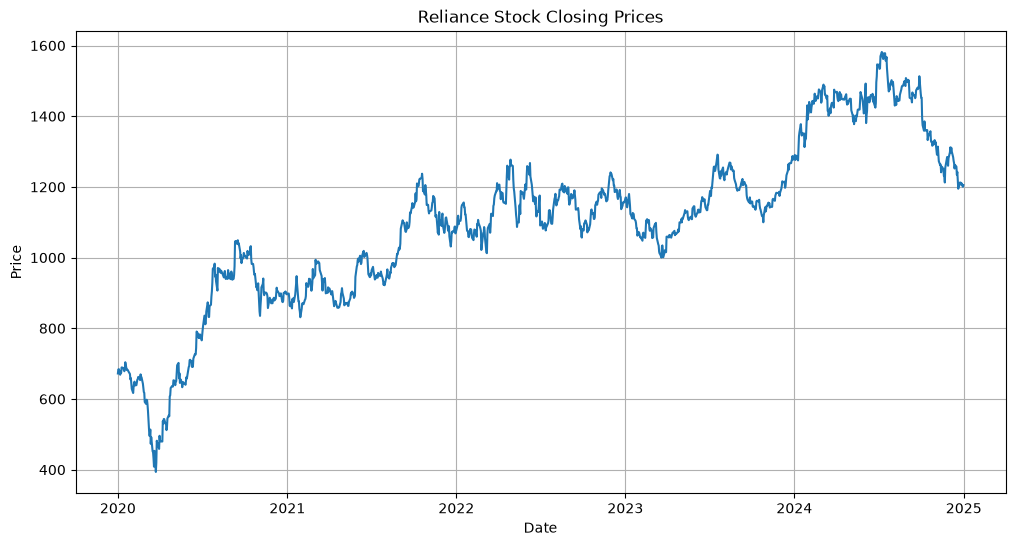

In [12]:
# ==========================================================
# STEP 12: Visualize Historical Stock Prices
# ==========================================================

plt.figure(figsize=(12, 6))

plt.plot(close_prices)

plt.title("Reliance Stock Closing Prices")

plt.xlabel("Date")
plt.ylabel("Price")

plt.grid(True)

plt.show()

In [13]:
# ==========================================================
# STEP 13: Create Lag Features
# ==========================================================

# Convert time-series data into supervised learning data.

df = pd.DataFrame({
    "Close": close_prices
})

# Create previous 60 days as features
for i in range(1, 61):
    df[f"Lag_{i}"] = df["Close"].shift(i)

# Target = next day's closing price
df["Target"] = df["Close"].shift(-1)

# Remove rows containing missing values
df = df.dropna()

print(df.head())
print("Dataset Shape:", df.shape)

                 Close       Lag_1       Lag_2       Lag_3       Lag_4  \
Date                                                                     
2020-03-25  481.919678  420.090607  393.662415  453.287231  408.646515   
2020-03-26  474.772705  481.919678  420.090607  393.662415  453.287231   
2020-03-27  474.505493  474.772705  481.919678  420.090607  393.662415   
2020-03-30  458.853455  474.505493  474.772705  481.919678  420.090607   
2020-03-31  495.946472  458.853455  474.505493  474.772705  481.919678   

                 Lag_5       Lag_6       Lag_7       Lag_8       Lag_9  ...  \
Date                                                                    ...   
2020-03-25  431.267487  448.856598  452.285339  492.183716  473.347748  ...   
2020-03-26  408.646515  431.267487  448.856598  452.285339  492.183716  ...   
2020-03-27  453.287231  408.646515  431.267487  448.856598  452.285339  ...   
2020-03-30  393.662415  453.287231  408.646515  431.267487  448.856598  ...   
2020-03

In [14]:
# ==========================================================
# STEP 14: Split Dataset into Training and Testing Sets
# ==========================================================

# 80% Training Data
# 20% Testing Data

train_size = int(len(df) * 0.8)

train = df.iloc[:train_size]

test = df.iloc[train_size:]

# Select lag features
features = [f"Lag_{i}" for i in range(1, 61)]

X_train = train[features]
y_train = train["Target"]

X_test = test[features]
y_test = test["Target"]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (995, 60)
Testing Data: (249, 60)


In [15]:
# ==========================================================
# STEP 15: Build XGBoost Model
# ==========================================================

# Create XGBoost regression model

model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

In [16]:
# ==========================================================
# STEP 16: Train XGBoost Model
# ==========================================================

# Train the model using historical training data

model.fit(X_train, y_train)

print("XGBoost Model Training Completed")

XGBoost Model Training Completed


In [17]:
# ==========================================================
# STEP 17: Predict Stock Prices
# ==========================================================

# Predict stock prices for the testing period

predictions = model.predict(X_test)

print("Predictions Generated Successfully")

print(predictions[:5])

Predictions Generated Successfully
[1330.5496 1344.6854 1340.4277 1337.6716 1331.1742]


In [18]:
# ==========================================================
# STEP 18: Calculate RMSE
# ==========================================================

# RMSE measures the prediction error.

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

print("RMSE =", rmse)

RMSE = 131.28547816553436


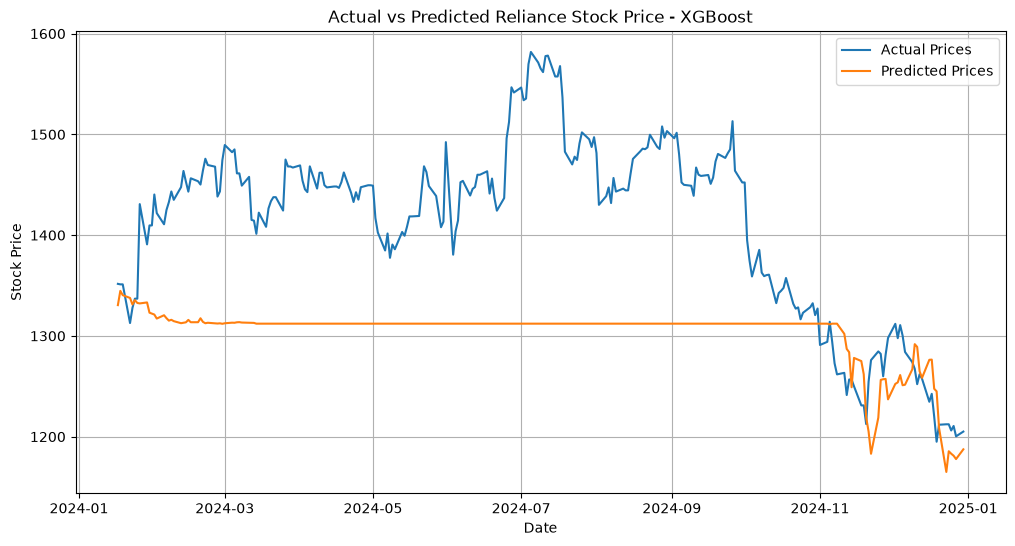

In [19]:
# ==========================================================
# STEP 19: Compare Actual vs Predicted Prices
# ==========================================================

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual Prices"
)

plt.plot(
    y_test.index,
    predictions,
    label="Predicted Prices"
)

plt.title("Actual vs Predicted Reliance Stock Price - XGBoost")

plt.xlabel("Date")
plt.ylabel("Stock Price")

plt.legend()

plt.grid(True)

plt.show()

In [20]:
# ==========================================================
# STEP 20: Forecast Future Stock Prices
# ==========================================================

# Generate stock price forecast
# for the next 30 business days

future_steps = 30

history = close_prices.tolist()

future_prices = []

for _ in range(future_steps):

    # Get the latest 60 prices
    recent_values = history[-60:]

    # Arrange latest price as Lag_1
    # and oldest price as Lag_60

    input_data = pd.DataFrame(
        [recent_values[::-1]],
        columns=features
    )

    # Predict next day's price
    next_price = model.predict(input_data)[0]

    future_prices.append(next_price)

    # Add prediction to history
    history.append(next_price)

future_dates = pd.bdate_range(
    start=close_prices.index[-1] + pd.offsets.BDay(1),
    periods=future_steps
)

future_predictions = pd.Series(
    future_prices,
    index=future_dates
)

print(future_predictions)

2025-01-01    1172.688965
2025-01-02    1144.683228
2025-01-03    1148.566162
2025-01-06    1145.480469
2025-01-07    1146.145020
2025-01-08    1143.893921
2025-01-09    1135.674072
2025-01-10    1136.481567
2025-01-13    1136.945557
2025-01-14    1128.930298
2025-01-15    1121.025879
2025-01-16    1115.948120
2025-01-17    1122.881592
2025-01-20    1118.002197
2025-01-21    1130.515137
2025-01-22    1140.317139
2025-01-23    1148.660156
2025-01-24    1162.215820
2025-01-27    1152.805908
2025-01-28    1149.570312
2025-01-29    1147.074829
2025-01-30    1154.781616
2025-01-31    1145.208130
2025-02-03    1150.759766
2025-02-04    1149.003174
2025-02-05    1145.816650
2025-02-06    1140.841919
2025-02-07    1137.617065
2025-02-10    1138.227905
2025-02-11    1135.911621
Freq: B, dtype: float32


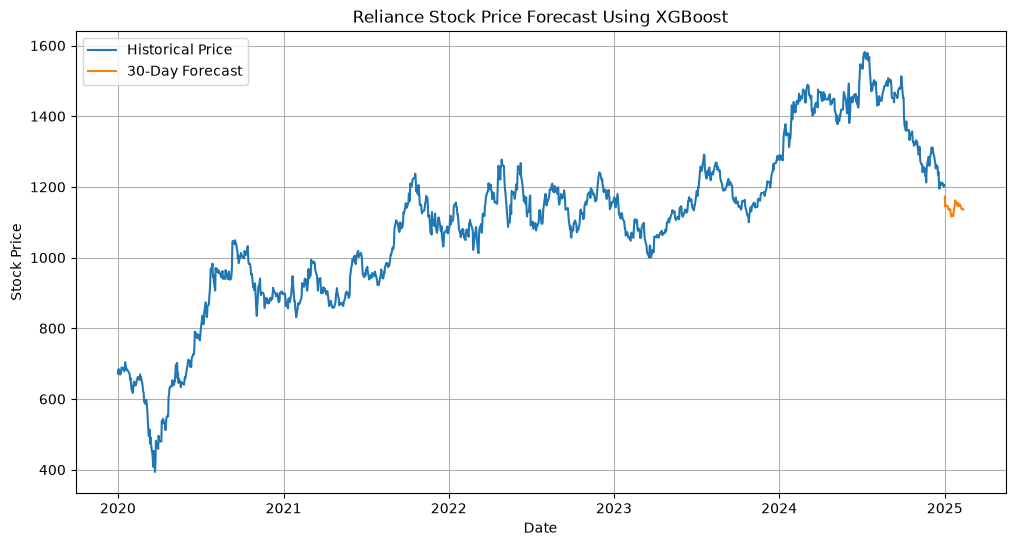

In [21]:
plt.figure(figsize=(12, 6))

plt.plot(
    close_prices,
    label="Historical Price"
)

plt.plot(
    future_predictions,
    label="30-Day Forecast"
)

plt.title("Reliance Stock Price Forecast Using XGBoost")

plt.xlabel("Date")
plt.ylabel("Stock Price")

plt.legend()

plt.grid(True)

plt.show()